# Grid search

Settings such as `C` and `gamma` change a Kernel SVM a lot. **Grid search** tries every combination you list and keeps the one with the best cross-validated score.

This notebook goes with the **Grid search** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

## 1. Load the data

Each row is a tumour sample from a breast biopsy. The columns are eight measurements of the cell nuclei (size, texture, shape). The goal: predict whether the sample is **malignant** (`diagnosis = 1`) or **benign** (`0`).

The data is the Breast Cancer Wisconsin (Diagnostic) data set from the UCI repository (CC BY 4.0), reduced to eight columns. This is a teaching example, not medical advice.

In [1]:
import numpy as np
import pandas as pd

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/breast_cancer.csv"
dataset = pd.read_csv(DATA_URL)
X = dataset.drop(columns="diagnosis")
y = dataset["diagnosis"]
print(dataset.shape)
dataset.head()

(569, 9)


,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430


## 2. Split off a test set

Grid search uses cross-validation *inside* the training data. The test set stays untouched until the very end.

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
print(X_train.shape, X_test.shape)

(426, 8) (143, 8)


## 3. Run the search

Every cell of the grid is a 5-fold cross-validation. Here that is 5 values of `C` times 5 values of `gamma` times 5 folds = 125 models. The scaler is part of the pipeline, so it is fitted inside each fold.

In [3]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

pipe = Pipeline([("scale", StandardScaler()), ("svm", SVC(kernel="rbf"))])
grid = {
    "svm__C": [0.1, 1, 10, 100, 1000],
    "svm__gamma": [0.001, 0.01, 0.1, 1, 10],
}
search = GridSearchCV(pipe, grid, cv=5, return_train_score=True)
search.fit(X_train, y_train)

print("best settings:", search.best_params_)
print(f"best CV accuracy: {search.best_score_:.3f}")

best settings: {'svm__C': 1000, 'svm__gamma': 0.01}
best CV accuracy: 0.953


## 4. Draw the heatmap

This is the same picture as on the lesson page: mean CV accuracy for every cell.

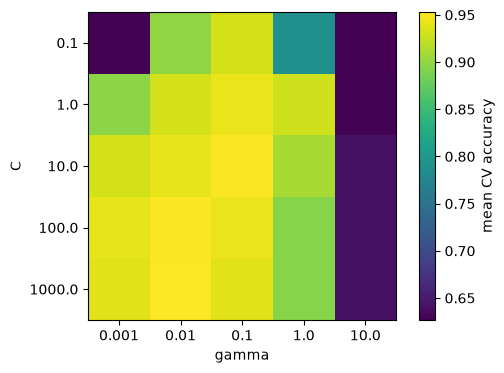

In [4]:
import matplotlib.pyplot as plt

res = pd.DataFrame(search.cv_results_)
cv_map = res.pivot(index="param_svm__C", columns="param_svm__gamma", values="mean_test_score")
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(cv_map.values, cmap="viridis")
ax.set_xticks(range(len(cv_map.columns)), cv_map.columns)
ax.set_yticks(range(len(cv_map.index)), cv_map.index)
ax.set_xlabel("gamma")
ax.set_ylabel("C")
fig.colorbar(im, label="mean CV accuracy")
plt.show()

## 5. The overfitting gap

Compare the training score with the CV score for every cell. A big gap means the model memorised the training folds.

In [5]:
res["gap"] = res["mean_train_score"] - res["mean_test_score"]
res.sort_values("gap", ascending=False)[["param_svm__C", "param_svm__gamma", "mean_train_score", "mean_test_score", "gap"]].head(5)

,param_svm__C,param_svm__gamma,mean_train_score,mean_test_score,gap
9,1.0,10.0,1.0,0.629138,0.370862
19,100.0,10.0,1.0,0.640876,0.359124
24,1000.0,10.0,1.0,0.640876,0.359124
14,10.0,10.0,1.0,0.640876,0.359124
18,100.0,1.0,1.0,0.894391,0.105609


## 6. Score the winner once on the test set

`GridSearchCV` refits the best settings on the whole training set, so `search` can predict directly.

In [6]:
print(f"test accuracy: {search.score(X_test, y_test):.3f}")

test accuracy: 0.944


## 7. Try it yourself

- Add `"svm__kernel": ["linear", "rbf"]` to the grid.
- Try `RandomizedSearchCV`, which samples cells instead of trying all of them. It is much faster for big grids.

## See it: the whole grid at once

**Left:** mean cross-validated accuracy for every `C` and `gamma` pair. The white star marks the best cell, the one `GridSearchCV` kept. **Right:** the gap between the training score and the CV score. **Notice how** a bright, high-accuracy cell can sit in a ridge of similar cells, and how the big gaps (memorising the training folds) are in the corner with the largest `gamma`.

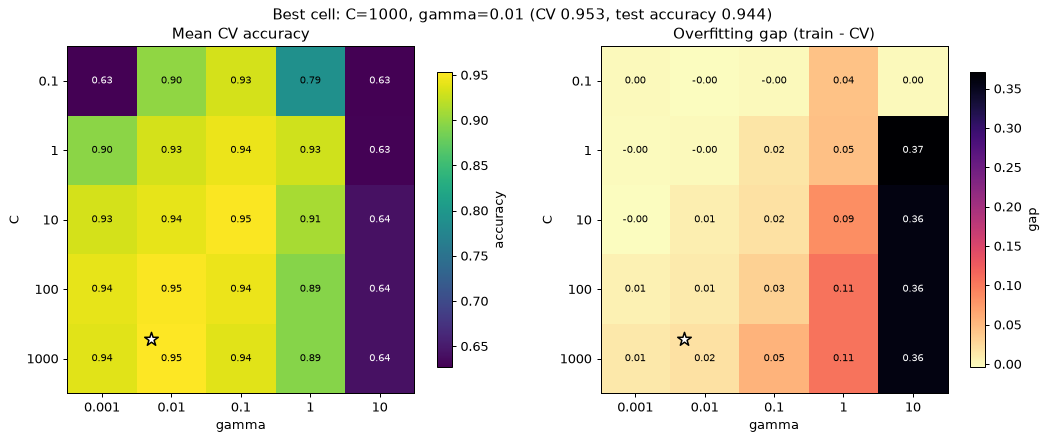

In [7]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt

C_values, gamma_values = grid['svm__C'], grid['svm__gamma']
shape = (len(C_values), len(gamma_values))
test_map = search.cv_results_['mean_test_score'].reshape(shape)
train_map = search.cv_results_['mean_train_score'].reshape(shape)
gap_map = train_map - test_map
bi, bj = np.unravel_index(search.best_index_, shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, data, cmap, title, label in [
        (axes[0], test_map, 'viridis', 'Mean CV accuracy', 'accuracy'),
        (axes[1], gap_map, 'magma_r', 'Overfitting gap (train - CV)', 'gap')]:
    im = ax.imshow(data, cmap=cmap)
    ax.set_xticks(range(shape[1]), gamma_values)
    ax.set_yticks(range(shape[0]), C_values)
    ax.set_xlabel('gamma'); ax.set_ylabel('C')
    ax.set_title(title)
    mid = (data.max() + data.min()) / 2
    for i in range(shape[0]):
        for j in range(shape[1]):
            dark = (data[i, j] < mid) == (cmap == 'viridis')
            ax.text(j, i, f'{data[i, j]:.2f}', ha='center', va='center', fontsize=8, color='white' if dark else 'black')
    ax.scatter([bj - 0.3], [bi - 0.28], marker='*', s=130, color='white', edgecolors='black', linewidths=1.2, zorder=5)
    fig.colorbar(im, ax=ax, label=label, shrink=0.85)
fig.suptitle(f"Best cell: C={C_values[bi]}, gamma={gamma_values[bj]} (CV {test_map[bi, bj]:.3f}, test accuracy {search.score(X_test, y_test):.3f})")
fig.tight_layout()
plt.show()
